# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import SARShipDetectionDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects with bounding boxes

Total number of patches: 39729


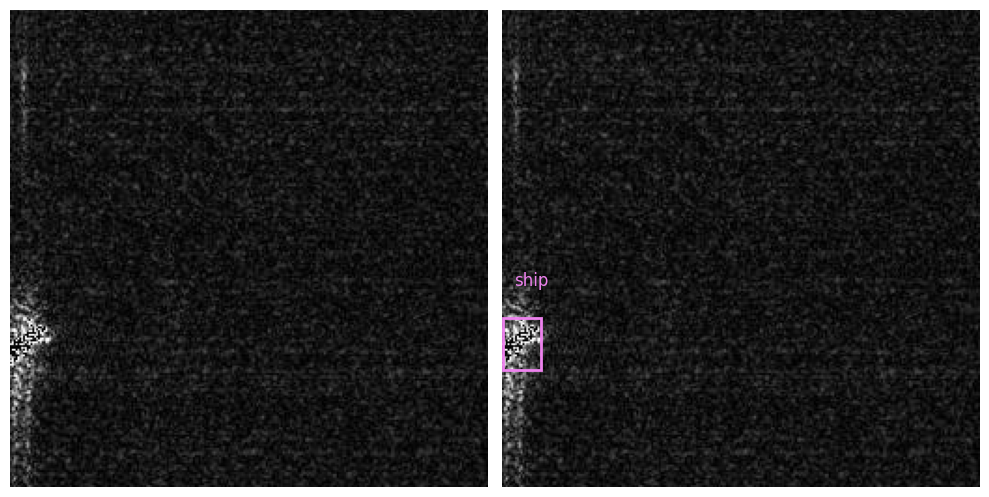

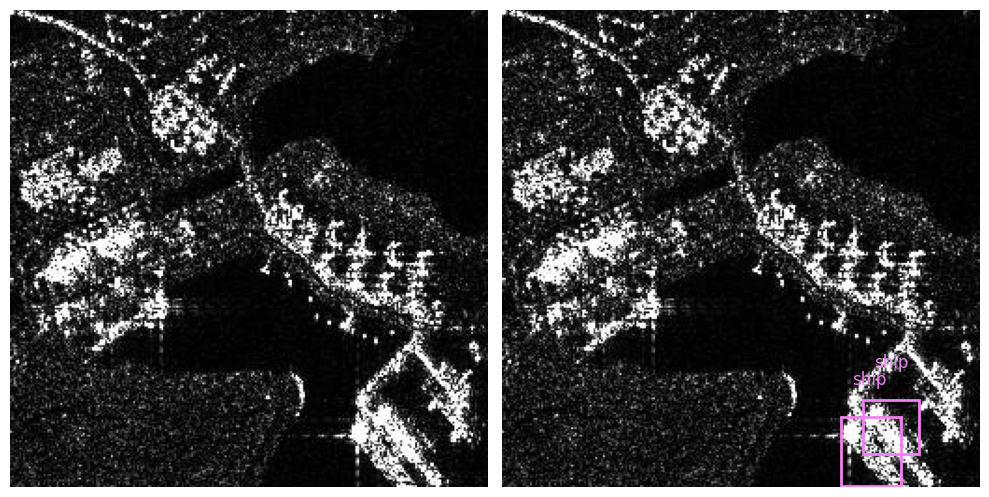

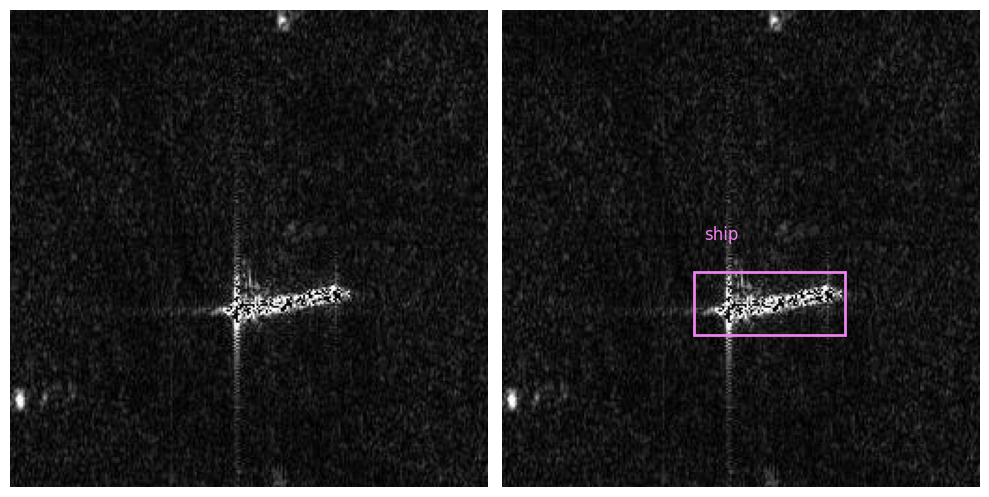

In [ ]:
dataset_config = {
    "data_dir": "./data/SAR_ship_detection/images/",
    "annotation_dir": "./data/SAR_ship_detection/labels/",
}
dataset = SARShipDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

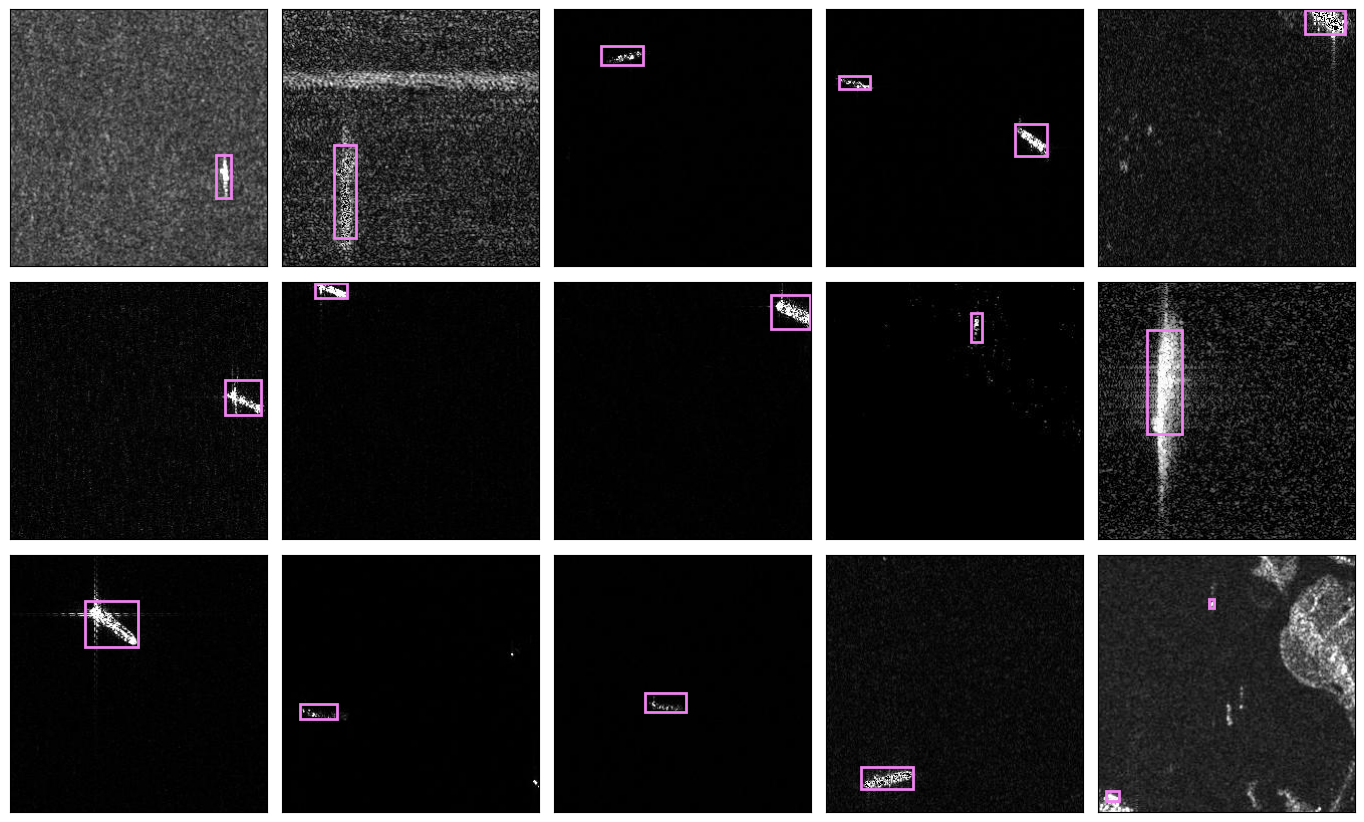

In [13]:
dataset.show_batch(15);

In [14]:
dataset.data_distribution_table()

,Label,Count
0,ship,50885


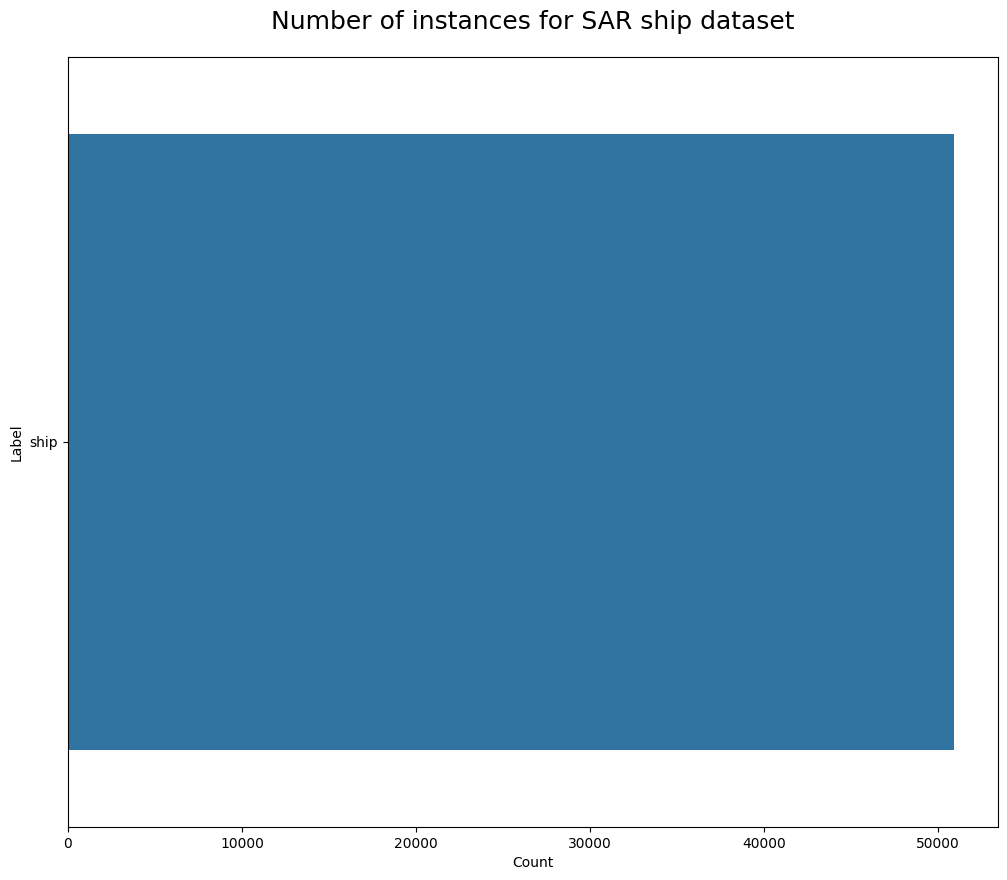

In [15]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/SAR_ship_detection/images/",
    "annotation_dir": "./data/SAR_ship_detection/labels/",
    "csv_file": "./data/SAR_ship_detection/sar_ship_detection_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SARShipDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 23837


## Create the model

In [ ]:
epochs = 5
model_directory = "./data/SAR_ship_detection/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-01-08 08:43:43,762 INFO Starting training.
training: 100%|██████████| 2980/2980 [36:45<00:00,  1.35it/s]
2026-01-08 09:20:29,985 INFO epoch: 1, time: 2205, loss:  0.12845
testing on train set: 100%|██████████| 2980/2980 [20:23<00:00,  2.44it/s]
2026-01-08 09:41:15,491 INFO map:0.5438862442970276, map_50:0.9367895722389221, map_75:0.5877323150634766, map_small:0.4387066066265106, map_medium:0.5543306469917297, map_large:0.5523765683174133, mar_1:0.4897783398628235, mar_10:0.6223172545433044, mar_100:0.6257190704345703, mar_small:0.5312284231185913, mar_medium:0.6383223533630371, mar_large:0.6021052598953247, map_per_class:0.5438862442970276, mar_100_per_class:0.6257190704345703, classes:1.0
training: 100%|██████████| 2980/2980 [34:37<00:00,  1.43it/s]
2026-01-08 10:15:53,298 INFO epoch: 2, time: 2078, loss:  0.11106
testing on train set: 100%|██████████| 2980/2980 [20:10<00:00,  2.46it/s]
2026-01-08 10:36:27,068 INFO map:0.5983608365058899, map_50:0.9552909135818481, map_75:0.68560

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/SAR_ship_detection/images/",
    "annotation_dir": "./data/SAR_ship_detection/labels/",
    "csv_file": "./data/SAR_ship_detection/sar_ship_detection_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SARShipDetectionDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/SAR_ship_detection/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 7946


2026-01-08 12:44:48,645 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar
2026-01-08 12:44:49,003 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 994/994 [02:46<00:00,  5.96it/s]


[{'map': 0.592383623123169,
  'map_50': 0.9462546110153198,
  'map_75': 0.6877543330192566,
  'map_small': 0.44340360164642334,
  'map_medium': 0.6071034669876099,
  'map_large': 0.605301558971405,
  'mar_1': 0.5236973762512207,
  'mar_10': 0.6557844877243042,
  'mar_100': 0.6575900316238403,
  'mar_small': 0.5241453051567078,
  'mar_medium': 0.67164546251297,
  'mar_large': 0.6648221611976624,
  'map_per_class': 0.592383623123169,
  'mar_100_per_class': 0.6575900316238403,
  'classes': 1.0}]

## Predictions

2026-01-08 14:21:34,252 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar
2026-01-08 14:21:34,523 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar at epoch 6


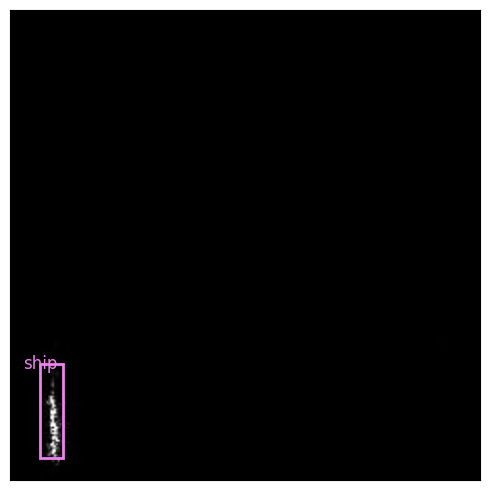

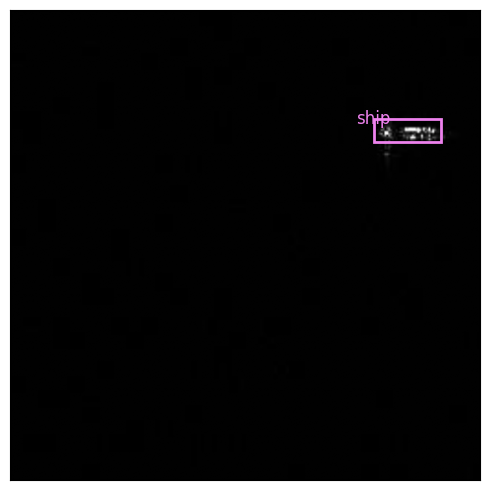

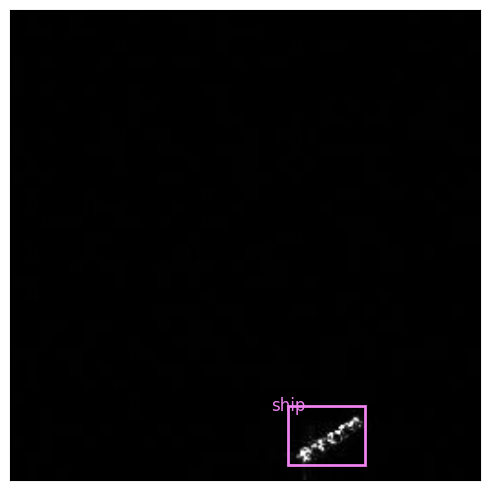

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/SAR_ship_detection/experiments/checkpoint.pth.tar"
labels = ["no-data","ship"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/SAR_ship_detection/sar_ship_detection_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/SAR_ship_detection/' + test_list[10])  
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/SAR_ship_detection/' + test_list[60])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/SAR_ship_detection/' + test_list[90])
fig = model.detect_objects(image, labels, transform)